# Створення нейронної мережі

У цьому завданні ми створимо повнозв'язну нейронну мережу, використовуючи при цьому низькорівневі механізми tensorflow.

Архітектура нейромережі представлена на наступному малюнку. Як бачиш, у ній є один вхідний шар, два приховані, а також вихідний шар. В якості активаційної функції у прихованих шарах буде використовуватись сигмоїда. На вихідному шарі ми використовуємо softmax.

Частина коду зі створення мережі вже написана, тобі потрібно заповнити пропуски у вказаних місцях.

## Архітектура нейронної мережі

<img src="http://cs231n.github.io/assets/nn1/neural_net2.jpeg" alt="nn" style="width: 400px;"/>


## Про датасет MNIST

Дану нейромережу ми будемо вивчати на датасеті MNIST. Цей датасет являє собою велику кількість зображень рукописних цифр розміром $28 \times 28$ пікселів. Кожен піксель приймає значення від 0 до 255.

Як і раніше, датасет буде розділений на навчальну та тестову вибірки. При цьому ми виконаємо нормалізацію всіх зображень, щоб значення пікселів знаходилось у проміжку від 0 до 1, розділивши яскравість кожного пікселя на 255.

Окрім того, архітектура нейронної мережі очікує на вхід вектор. У нашому ж випадку кожен об'єкт вибірки являє собою матрицю. Що ж робити? У цьому завданні ми "розтягнемо" матрицю $28 \times 28$, отримавши при цьому вектор, що складається з 784 елементів.

![MNIST Dataset](https://www.researchgate.net/profile/Steven-Young-5/publication/306056875/figure/fig1/AS:393921575309346@1470929630835/Example-images-from-the-MNIST-dataset.png)

Більше інформації про датасет можна знайти [тут](http://yann.lecun.com/exdb/mnist/).

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import keras as K
import seaborn as sns
from sklearn.metrics import classification_report

In [2]:
num_classes = 10 # загальна кількість класів, у нашому випадку це цифри від 0 до 9
num_features = 784 # кількість атрибутів вхідного вектора 28 * 28 = 784

learning_rate = 0.001 # швидкість навчання нейронної мережі
training_steps = 3000 # максимальне число епох
batch_size = 256 # перераховувати ваги мережі ми будемо не на всій вибірці, а на її випадковій підмножині з batch_size елементів
display_step = 100 # кожні 100 ітерацій ми будемо показувати поточне значення функції втрат і точності

n_hidden_1 = 128 # кількість нейронів 1-го шару
n_hidden_2 = 256 # кількість нейронів 2-го шару

In [3]:
# from tensorflow.keras.datasets import mnist
from keras.datasets import mnist

# Завантажуємо датасет
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Перетворюємо цілочисельні пікселі на тип float32
x_train, x_test = np.array(x_train, np.float32), np.array(x_test, np.float32)

# Перетворюємо матриці розміром 28x28 пікселів у вектор з 784 елементів
x_train, x_test = x_train.reshape([-1, num_features]), x_test.reshape([-1, num_features])

# Нормалізуємо значення пікселів
x_train, x_test = x_train / 255., x_test / 255.

# Перемішаємо тренувальні дані
train_data = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_data = train_data.repeat().shuffle(5000).batch(batch_size).prefetch(1)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
# Створимо нейронну мережу

class DenseLayer(tf.Module):
    def __init__(self, in_features, out_features, name=None):
        super().__init__(name=name)
        self.w = tf.Variable(
            tf.random.normal([in_features, out_features]), name="w"
        )
        self.b = tf.Variable(tf.zeros([out_features]), name="b")

    def __call__(self, x, activation=0):
        y = tf.matmul(x, self.w) + self.b
        if activation != 0:
            return tf.nn.softmax(y)
        else:
            return tf.nn.sigmoid(y)

class NN(tf.Module):
  def __init__(self, name=None):
    super().__init__(name=name)
    # Перший шар, який складається з 128 нейронів
    self.layer_1 = DenseLayer(in_features=784, out_features=128)
    # Другий шар, який складається з 256 нейронів
    self.layer_2 = DenseLayer(in_features=128, out_features=256)
    # Вихідний шар
    self.output = DenseLayer(in_features=256, out_features=10)


  def __call__(self, x):
    # Передача даних через перші два шари та вихідний шар з функцією активації softmax
    x1 = self.layer_1(x, activation=0)
    x2 = self.layer_2(x1, activation=0)
    x3 = self.output(x2, activation=1)

    return x3

In [5]:
# В якості функції помилки в даному випадку зручно взяти крос-ентропію
def cross_entropy(y_pred, y_true):
    # Закодувати label в one hot vector
    y_true = tf.one_hot(y_true, depth=num_classes)

    # Значення передбачення, щоб уникнути помилки log(0).
    y_pred = tf.clip_by_value(y_pred, 1e-9, 1.)

    # Обчислення крос-ентропії
    return tf.reduce_mean(-tf.reduce_sum(y_true * tf.math.log(y_pred)))

# Як метрику якості використовуємо точність
def accuracy(y_pred, y_true):
    acc = tf.metrics.Accuracy()
    acc.update_state(y_true, tf.argmax(y_pred, axis=1))
    return acc.result()

In [6]:
# Створимо екземпляр нейронної мережі
neural_net = NN(name="mnist")

# Функція навчання нейромережі
def train(neural_net, input_x, output_y):
  # Для налаштування вагів мережі будемо використовувати стохастичний градієнтний спуск
  optimizer = tf.optimizers.SGD(learning_rate)

  # Активація автоматичного диференціювання
  with tf.GradientTape() as g:
    pred = neural_net(input_x)
    loss = cross_entropy(pred, output_y)

    # Отримаємо список оптимізованих параметрів
    trainable_variables = neural_net.trainable_variables
    # Обчислимо за ними значення градієнта
    gradients = g.gradient(loss, trainable_variables)

    # Модифікуємо параметри
    optimizer.apply_gradients(zip(gradients, trainable_variables))

In [7]:
# Тренування мережі

loss_history = []  # кожні display_step кроків зберігай в цьому списку поточну помилку нейромережі
accuracy_history = [] # кожні display_step кроків зберігай в цьому списку поточну точність нейромережі

# У цьому циклі ми будемо проводити навчання нейронної мережі
# із тренувального датасета train_data вилучи випадкову підмножину, на якій
# відбудеться тренування. Використовуй метод take, доступний для тренувального датасета.
for step, (batch_x, batch_y) in enumerate(train_data.take(training_steps)):
    # Оновлюємо ваги нейронної мережі
    train(neural_net, batch_x, batch_y)

    if step % display_step == 0:
        pred = neural_net(batch_x)
        current_loss = cross_entropy(pred, batch_y)
        current_accuracy = accuracy(pred, batch_y)
        loss_history.append(current_loss)
        accuracy_history.append(current_accuracy)

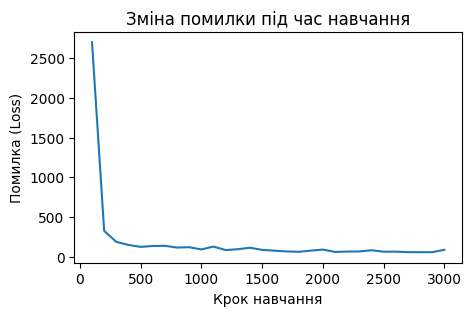

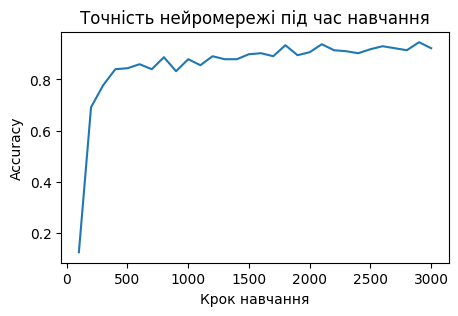

In [13]:
# Виведіть графіки залежності зміни точності і втрат від кроку
# Якщо все зроблено правильно, то точність повинна зростати, а втрати зменшуватись

import matplotlib.pyplot as plt

# Виведіть графік функції втрат
plt.figure(figsize=(5, 3))

plt.plot(
    range(display_step, training_steps + 1, display_step),
    loss_history,
)

plt.xlabel("Крок навчання")
plt.ylabel("Помилка (Loss)")
plt.title("Зміна помилки під час навчання")
plt.show()

# Виведіть графік точності
plt.figure(figsize=(5, 3))

plt.plot(
    range(display_step, training_steps + 1, display_step),
    accuracy_history,
)

plt.xlabel("Крок навчання")
plt.ylabel("Accuracy")
plt.title("Точність нейромережі під час навчання")
plt.show()

# fig, axs = plt.subplots(figsize=(16, 10))
# axs.plot(loss_history, 'r', label='loss', linestyle=":")
# axs.legend()

# axs2=axs.twinx()
# axs2.plot(accuracy_history, 'b', label='accuracy', linestyle=":")
# plt.legend()

# plt.title('Залежності зміни точності та втрат від кроку', fontsize=20, color='g')
# plt.show()


In [9]:
# Обчисліть точність навченої нейромережі
train_pred = neural_net(x_train)
train_acc = accuracy(train_pred, y_train)
print("Training accuracy:", train_acc.numpy())
# Тестування моделі на тестових даних
test_pred = neural_net(x_test)
test_acc = accuracy(test_pred, y_test)
print("Test accuracy:", test_acc.numpy())

Training accuracy: 0.9216
Test accuracy: 0.9002


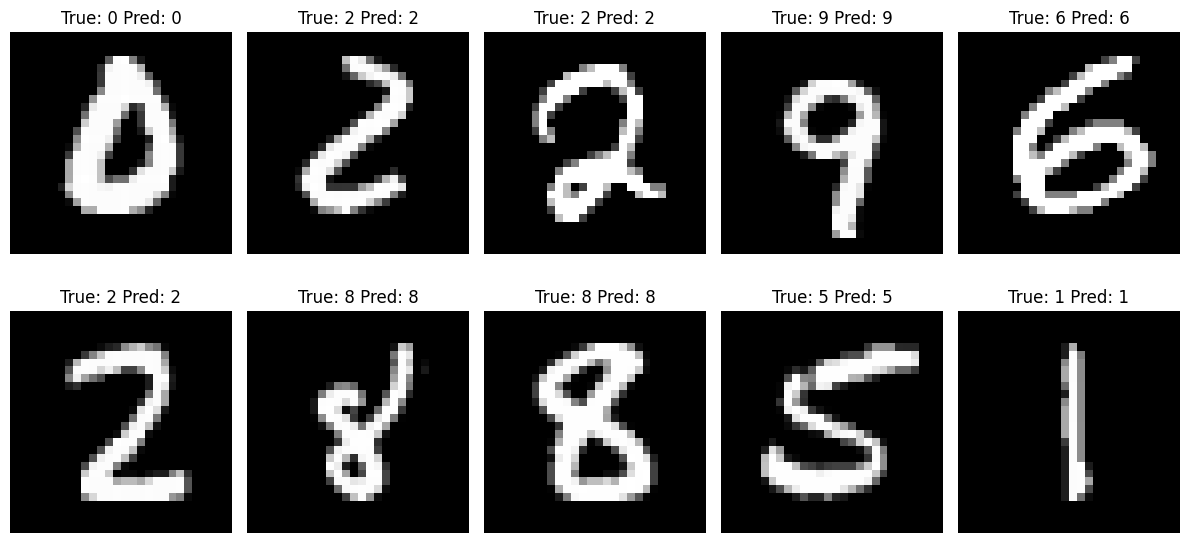

In [17]:
# Протестуйте навчену нейромережу на 10 зображеннях. З тестової вибірки візьміть 5
# випадкових зображень і передайте їх у нейронну мережу.
# Виведіть зображення та випишіть  поруч відповідь нейромережі.
# Зробіть висновок про те, чи помиляється твоя нейронна мережа, і якщо так, то як часто?

random_img = np.random.choice(
    len(x_test), size=10, replace=False
)

ten_test_x = x_test[random_img]
ten_test_y = y_test[random_img]

ten_test_pred = neural_net(ten_test_x)
predicted_digits = tf.argmax(ten_test_pred, axis=1)

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(ten_test_x[i].reshape(28, 28), cmap="gray")

    plt.title(
        f"True: {ten_test_y[i]} Pred: {predicted_digits[i].numpy()}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# Сlassification_report

In [11]:
y_pred = tf.argmax(test_pred, axis=1).numpy()

print(classification_report(
    y_test,
    y_pred,
    labels=range(10),
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.92      0.96      0.94       980
           1       0.97      0.97      0.97      1135
           2       0.89      0.90      0.90      1032
           3       0.91      0.86      0.88      1010
           4       0.89      0.91      0.90       982
           5       0.85      0.88      0.87       892
           6       0.93      0.92      0.93       958
           7       0.89      0.91      0.90      1028
           8       0.86      0.85      0.85       974
           9       0.88      0.84      0.86      1009

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



# Висновок
Нейронна мережа доволі добре розпізнає рукописні цифри. Точність на навчальній вибірці становить 0.9216, а на тестовій — 0.9002. На візуалізації зміни помилки та точності під час навчання прослідковується тенденція зростання точності і спадання похибки під час кроків навчання, коливання на окремих кроках навчання присутні, але дуже незначні. Візуалізація вище підтвердила, що модель не помиляється і завжди правильно розпізнає зображення. За результатами classification_report найвищий показник F1-score спостерігається для цифри 1 і становить 0.97, що свідчить про найкраще її розпізнавання. Найнижчий показник F1-score має тепер цифра 8 і становить 0.85, але показник все ще високий.